In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch
import xarray as xa

import sys,os
testdir = os.path.dirname(os.getcwd() + '/')
srcdir = '..'
sys.path.insert(0, os.path.abspath(os.path.join(testdir, srcdir)))
from ocean_wave_tracing import Wave_tracing

from ocean_wave_tracing.util_metric import SphericalMetric

%matplotlib widget


In [2]:
#WRONG
def great_circle_latitude(lon, startlat, bearing):
    lat = np.arctan2(np.tan(startlat)*np.cos(lon) + np.cos(bearing)*np.sin(lon), (np.cos(startlat)*np.sin(bearing)))
    return lat

In [3]:
lons_trajectory = np.linspace(0,360,1000)
lats_trajectory = np.rad2deg(great_circle_latitude(lon=np.deg2rad(lons_trajectory), startlat=np.deg2rad(40), bearing=np.deg2rad(45)))

In [4]:
# Make data
lons = np.linspace(0, 2 * np.pi, 100)
lats = np.linspace(0, np.pi, 100)
x = np.outer(np.cos(lons), np.sin(lats))
y = np.outer(np.sin(lons), np.sin(lats))
z = np.outer(np.ones(np.size(lons)), np.cos(lats))

r_trajectory = 1.01
x_trajectory = r_trajectory*np.cos(np.deg2rad(lats_trajectory))*np.cos(np.deg2rad(lons_trajectory))
y_trajectory = r_trajectory*np.cos(np.deg2rad(lats_trajectory))*np.sin(np.deg2rad(lons_trajectory))
z_trajectory = r_trajectory*np.sin(np.deg2rad(lats_trajectory))

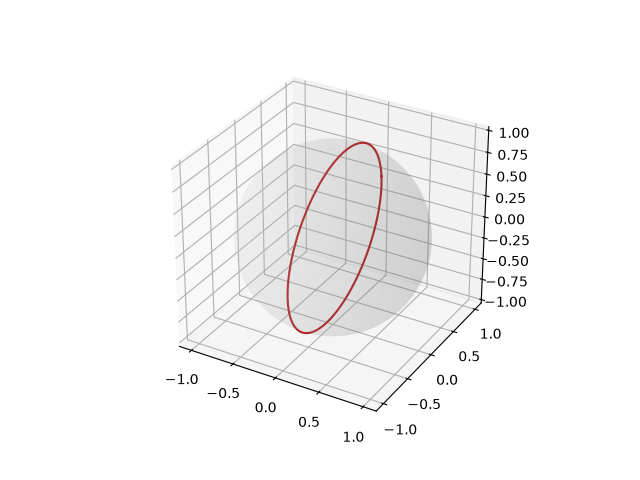

In [5]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Plot the surface
ax.plot_surface(x, y, z, color="lightgray", alpha=0.1)

ax.plot(x_trajectory, y_trajectory, z_trajectory, color="firebrick")

#plot the 

# Set an equal aspect ratio
ax.set_aspect('equal')

plt.show()

torch.Size([2000, 10])


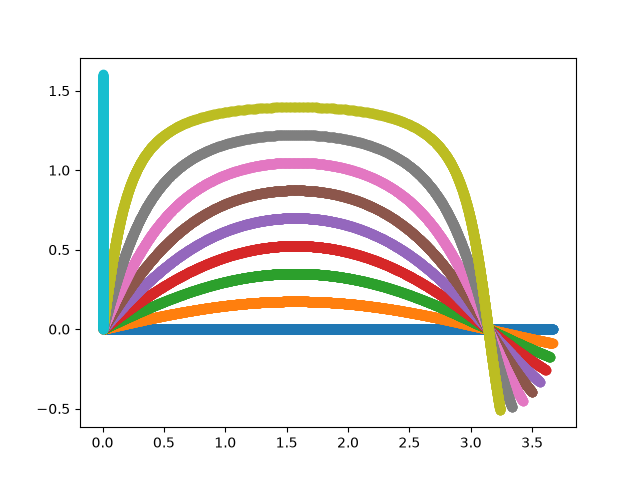

In [9]:
X = np.linspace(0, 2 * np.pi, 100)
Y = np.linspace(-np.pi/2, np.pi/2, 100)

theta0 = np.linspace(0, np.pi/2, 10)

nx = len(X)
ny = len(Y)

U = np.zeros((ny, nx))
V = np.zeros_like(U)

dx=X[1]-X[0]
dy=Y[1]-Y[0]
nb_wave_rays = len(theta0)#550#nx
T = 2000000
nt = 2000 # 1500
wave_period = 15 #s
X0, XN = X[0], X[-1] 
Y0, YN = Y[0], Y[-1]

# Sphere without current field
wt_idealized = Wave_tracing(U, V, nx, ny, nt,T,dx,dy, nb_wave_rays=nb_wave_rays,
                     domain_X0=X0, domain_XN=XN,
                     domain_Y0=Y0, domain_YN=YN,
                     metric=SphericalMetric())
wt_idealized.set_initial_condition(wave_period, theta0=theta0, ipx=0, ipy=0)
wt_idealized.solve()

print(np.shape(wt_idealized.ray_x.T))

fig, ax = plt.subplots()
for ray_x, ray_y in zip(wt_idealized.ray_x, wt_idealized.ray_y):
    ax.scatter(ray_x, ray_y)

In [7]:
print("Initial kx, ky:", wt_idealized.initial_rays[0, 2:])
print("Final kx, ky:", wt_idealized.rays[-1, 0, 2:])
print("Group velocity:", wt_idealized.ray_cg[0, 0])
print("Ray displacement:", wt_idealized.ray_x[0, -1].item(),
      wt_idealized.ray_y[0, -1].item())

Initial kx, ky: tensor([113950.3906,      0.0000])
Final kx, ky: tensor([113950.3906,      0.0000])
Group velocity: tensor(11.7098)
Ray displacement: 0.03674213960766792 0.0
